# Практическая работа 14. Простейшие нейронные сети

### 1. Генерация и визуализация данных
Классификация относится к обучению с учителем: для каждого объекта известен его класс. Сгенерируем 1000 объектов двух классов с помощью make_moons. Параметр noise задаёт уровень шума.

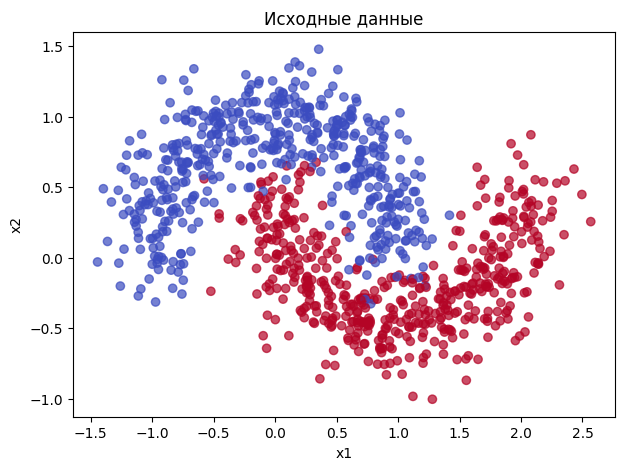

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, GridSearchCV, PredefinedSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline

X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', alpha=0.7)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Исходные данные')
plt.show()

Разделим данные на обучающую (60%), валидационную (20%) и тестовую (20%) выборки. На обучающей выборке настраиваются веса, на валидационной подбирается архитектура, а на тестовой проверяется итоговое качество.

Используем StandardScaler внутри модели, чтобы параметры нормализации вычислялись только по обучающим данным.

In [2]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)
print('Обучающая выборка:', len(X_train))
print('Валидационная выборка:', len(X_val))
print('Тестовая выборка:', len(X_test))

Обучающая выборка: 600
Валидационная выборка: 200
Тестовая выборка: 200


### 2. Логистическая регрессия
Логистическая регрессия — линейный классификатор. Вероятность принадлежности к классу 1 вычисляется с помощью сигмоиды:

$$z=w_1x_1+w_2x_2+b,\qquad p=\frac{1}{1+e^{-z}}$$

Если $p\geq 0.5$, объект относится к классу 1, иначе — к классу 0. Граница между классами является прямой.

Качество оценим с помощью accuracy — доли правильно классифицированных объектов:

$$Accuracy=\frac{N_{correct}}{N}$$

Accuracy: 0.88


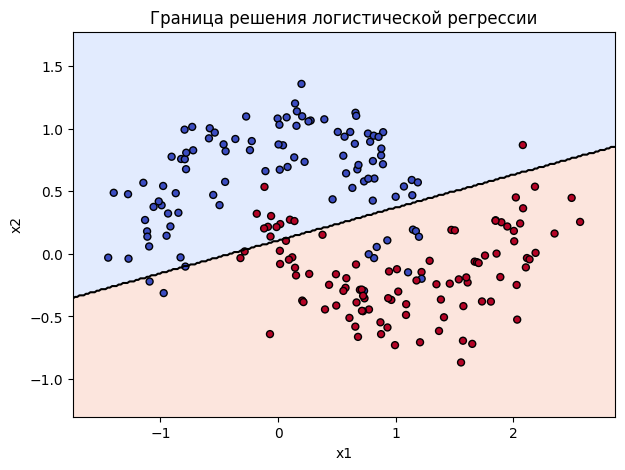

In [3]:
log_model = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))
log_model.fit(X_train, y_train)
log_acc = accuracy_score(y_test, log_model.predict(X_test))
print('Accuracy:', log_acc)

# Сетка точек для построения границы решения
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min()-0.3, X[:, 0].max()+0.3, 250),
    np.linspace(X[:, 1].min()-0.3, X[:, 1].max()+0.3, 250))
grid = np.c_[xx.ravel(), yy.ravel()]

def plot_boundary(model, title):
    Z = model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], cmap='coolwarm', alpha=0.25)
    plt.contour(xx, yy, Z, levels=[0.5], colors='black')
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', edgecolors='k', s=25)
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.title(title)
    plt.show()

plot_boundary(log_model, 'Граница решения логистической регрессии')

Граница решения является прямой, поэтому часть объектов двух классов классифицируется неправильно. Для таких данных нужна нелинейная модель.

### 3. Многослойный перцептрон
Нейрон вычисляет взвешенную сумму входных сигналов и применяет функцию активации:

$$z=\sum_{i=1}^{N}w_ix_i+b,\qquad y=f(z)$$

где $x_i$ — входные значения, $w_i$ — веса, $b$ — смещение.

Многослойный перцептрон состоит из входного, скрытых и выходного слоёв. Нелинейная функция активации позволяет строить сложные границы решения. Используем ReLU:

$$f(z)=\max(0,z)$$

При обучении методом обратного распространения ошибки вычисляются градиенты функции ошибки по весам.

$$w_i\leftarrow w_i-\eta\frac{\partial E}{\partial w_i}$$

где $\eta$ — коэффициент обучения. В MLPClassifier используем оптимизатор Adam, который адаптирует шаг обновления весов. Создадим два скрытых слоя по 16 нейронов.

Accuracy логистической регрессии: 0.88
Accuracy нейронной сети: 0.975


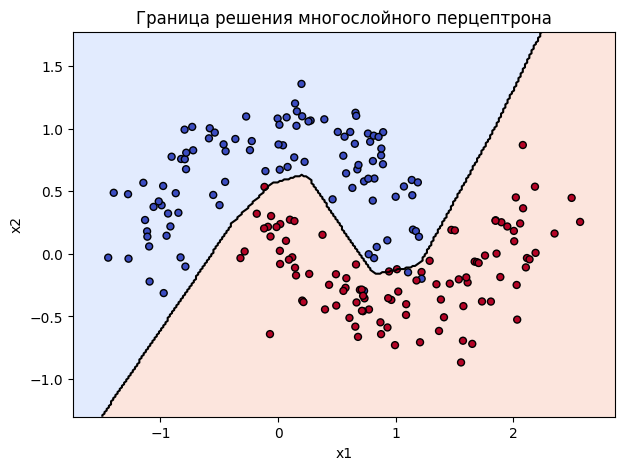

In [4]:
mlp = make_pipeline(StandardScaler(), MLPClassifier(
    hidden_layer_sizes=(16, 16), activation='relu',
    solver='adam', max_iter=2000, random_state=42))
mlp.fit(X_train, y_train)
mlp_acc = accuracy_score(y_test, mlp.predict(X_test))
print('Accuracy логистической регрессии:', log_acc)
print('Accuracy нейронной сети:', mlp_acc)
plot_boundary(mlp, 'Граница решения многослойного перцептрона')